# Chicago Food Inspections: exploratory data analysis

This notebook profiles the City of Chicago Food Inspections export (Chicago Data Portal dataset `4ijn-s7e5`, downloaded 2026-11-02) to inform the design of the inspection ranking pipeline. It covers data quality, the target definition, the main categorical drivers, time trends including the July 2018 food code change, the structure of the violations field, establishment history, geography, and the train, validation, and test split with simple ranking baselines. Each section ends with a short summary of what the outputs show, and the last two sections record the decisions taken and those still open.

Run locally, the notebook expects to start from the `eda/` folder with the CSV in `data/`, and writes figures to `results/eda/`. In Google Colab, set `COLAB_PROJECT_DIR` in the setup cell to the project folder on Google Drive. The setup cell then mounts Drive, reads the CSV from `data/` in that folder, and writes figures to `results/eda/` in the same folder.

## Setup

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

# COLAB_PROJECT_DIR must be set before running in Google Colab: the project
# folder on the mounted Google Drive, for example
# '/content/drive/MyDrive/<path to project folder>'. Run locally from
# eda/, the project folder is the repository and this value is not used.
COLAB_PROJECT_DIR = ''

try:
    from google.colab import drive
    drive.mount('/content/drive')
    assert COLAB_PROJECT_DIR, 'Set COLAB_PROJECT_DIR in the setup cell to the project folder on Drive.'
    PROJECT_SRC = Path(COLAB_PROJECT_DIR)
except ImportError:
    PROJECT_SRC = Path('..')

DATA_PATH = PROJECT_SRC / 'data' / 'Food_Inspections_20261102.csv'
FIG_DIR = PROJECT_SRC / 'results' / 'eda'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Print file and folder names only, so saved output carries no local paths.
print('Data file:', DATA_PATH.name, '| exists:', DATA_PATH.exists())
print('Figures folder:', FIG_DIR.name)

# Chicago adopted the FDA Food Code on this date, which renumbered the violation list.
FOOD_CODE_CHANGE = pd.Timestamp('2018-07-01')


def save(fig, name):
    """Tighten the layout and write the figure to FIG_DIR as a PNG."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=120)


def rate_table(frame, col, target='fail', top=15):
    """Row count and target rate per category, largest categories first."""
    out = frame.groupby(col, dropna=False)[target].agg(n='size', fail_rate='mean')
    return out.sort_values('n', ascending=False).head(top).round(3)

Mounted at /content/drive
Data file: Food_Inspections_20261102.csv | exists: True
Figures folder: eda


## Load

`Location` repeats latitude and longitude as a string, so it is dropped on load. IDs, license numbers, and ZIP codes are read as strings so leading zeros and odd values survive.

In [2]:
raw = pd.read_csv(
    DATA_PATH,
    dtype={'Inspection ID': 'string', 'License #': 'string', 'Zip': 'string'},
    usecols=lambda c: c != 'Location',
)
raw.columns = [c.lower().replace(' #', '_number').replace(' ', '_') for c in raw.columns]
raw['inspection_date'] = pd.to_datetime(raw['inspection_date'], format='%m/%d/%Y')

print(raw.shape)
raw.dtypes

(317961, 16)


,0
inspection_id,string[python]
dba_name,object
aka_name,object
license_number,string[python]
facility_type,object
risk,object
address,object
city,object
state,object
zip,string[python]


In [3]:
raw.head(3).T

,0,1,2
inspection_id,2646070,2646009,2646019
dba_name,D FRUTA LA VIDA LLC,NIGHT HERON,TINY TOTS UNIVERSITY
aka_name,D FRUTA LA VIDA,NIGHT HERON,TINY TOTS UNIVERSITY
license_number,2398055,3082882,2797573
facility_type,Restaurant,Restaurant,Children's Services Facility
risk,Risk 1 (High),Risk 2 (Medium),Risk 1 (High)
address,3739 W FULLERTON AVE,5499 S CORNELL AVE,7548 S MAY ST
city,CHICAGO,Chicago,CHICAGO
state,IL,IL,IL
zip,60647,60615,60620


## Data quality

In [4]:
quality = pd.DataFrame({
    'missing': raw.isna().sum(),
    'missing_pct': (raw.isna().mean() * 100).round(2),
    'n_unique': raw.nunique(),
})
quality

,missing,missing_pct,n_unique
inspection_id,0,0.00,317961
dba_name,0,0.00,35270
aka_name,2425,0.76,33559
license_number,19,0.01,49310
facility_type,5354,1.68,527
risk,88,0.03,4
address,0,0.00,33338
city,185,0.06,96
state,76,0.02,7
zip,42,0.01,141


In [5]:
lic = raw['license_number'].str.strip()

print('Date range:', raw['inspection_date'].min().date(), 'to', raw['inspection_date'].max().date())
print('Duplicate inspection IDs:', raw['inspection_id'].duplicated().sum())
print('Fully duplicated rows:', raw.duplicated().sum())
print('License missing or 0:', (lic.isna() | lic.isin(['0', '0.0'])).sum())
print('Rows without coordinates:', raw['latitude'].isna().sum())
print()
print(raw['city'].str.upper().str.strip().value_counts(dropna=False).head(10))
print()
print(raw['state'].value_counts(dropna=False).head())

Date range: 2010-01-04 to 2026-10-29
Duplicate inspection IDs: 0
Fully duplicated rows: 0
License missing or 0: 859
Rows without coordinates: 1064

city
CHICAGO              317378
NaN                     185
CCHICAGO                 62
SCHAUMBURG               30
EVANSTON                 28
MAYWOOD                  16
ELK GROVE VILLAGE        13
OAK PARK                 12
CHICAGOCHICAGO           12
CHICAGOO                 11
Name: count, dtype: int64

state
IL     317860
NaN        76
IN         13
CA          6
WI          3
Name: count, dtype: int64


In [6]:
# Chicago sits roughly within latitude 41.64 to 42.03 and longitude -87.94 to -87.52.
raw[['latitude', 'longitude']].describe().round(4)

,latitude,longitude
count,316897.0000,316897.0000
mean,41.8805,-87.6763
std,0.0808,0.0584
min,41.6447,-87.9069
25%,41.8318,-87.7073
50%,41.8917,-87.6663
75%,41.9395,-87.6349
max,42.0211,-87.5251


### Data quality findings

The export holds 317,961 inspections from 2010-01-04 to 2026-10-29, with no duplicate inspection IDs and no fully duplicated rows. The remaining issues are the following:

- Violations are empty for 89,776 rows (28.2%). Part of this comes from visits with no outcome, and the violations section checks the modeling rows separately.
- 859 rows have a missing or zero license number, so they cannot be linked to earlier inspections.
- 1,064 rows (0.3%) have no coordinates. Every coordinate present falls inside the Chicago bounding box (latitude 41.645 to 42.021, longitude -87.907 to -87.525), so these bounds can serve as valid-range checks in the monitoring stage.
- City and state are free text with typos (CCHICAGO, CHICAGOO, CHICAGOCHICAGO) and a few suburban or out-of-state values. Neither field is a planned feature, so they are left as is.
- Facility type has 527 raw values and is missing for 5,354 rows (1.7%).

## Results and target definition

Out of Business, No Entry, Not Ready, and Business Not Located record visits where no inspection outcome was produced, so the modeling rows are Pass, Pass w/ Conditions, and Fail. The table below compares two candidate targets: Fail alone, and Fail or Pass w/ Conditions.

In [7]:
results = raw['results'].value_counts(dropna=False).to_frame('count')
results['pct'] = (results['count'] / results['count'].sum() * 100).round(1)
results

,count,pct
results,,
Pass,164640,51.8
Fail,61209,19.3
Pass w/ Conditions,47092,14.8
Out of Business,25993,8.2
No Entry,14281,4.5
Not Ready,4650,1.5
Business Not Located,96,0.0


In [8]:
MODEL_RESULTS = ['Pass', 'Pass w/ Conditions', 'Fail']

df = raw[raw['results'].isin(MODEL_RESULTS)].copy()
df['fail'] = (df['results'] == 'Fail').astype(int)
df['fail_or_conditions'] = df['results'].isin(['Fail', 'Pass w/ Conditions']).astype(int)
df['year'] = df['inspection_date'].dt.year

print(f'Modeling rows: {len(df):,} of {len(raw):,}')
print(f'Fail rate: {df.fail.mean():.3f}')
print(f'Fail or conditions rate: {df.fail_or_conditions.mean():.3f}')

Modeling rows: 272,941 of 317,961
Fail rate: 0.224
Fail or conditions rate: 0.397


### Target findings

Pass, Fail, and Pass w/ Conditions make up 272,941 of 317,961 rows (85.8%). Fail alone has a positive rate of 22.4%, and Fail or Pass w/ Conditions has 39.7%. The time-trend section shows that the combined target shifts sharply at the 2018 food code change, so the later sections treat Fail as the target.

## Inspection type, facility type, and risk

Free-text categories are lowercased and stripped before grouping. Re-inspections are scheduled after a failed or conditional result, so inspection type carries information about the previous outcome. That information is available before the visit and can be used as a feature.

In [9]:
df['inspection_type_clean'] = df['inspection_type'].str.lower().str.strip()
df['facility_type_clean'] = df['facility_type'].str.lower().str.strip()

print('Distinct inspection types:', df['inspection_type_clean'].nunique())
rate_table(df, 'inspection_type_clean')

Distinct inspection types: 94


,n,fail_rate
inspection_type_clean,,
canvass,132742,0.226
license,37373,0.339
canvass re-inspection,34995,0.088
complaint,28490,0.352
license re-inspection,12770,0.108
complaint re-inspection,12551,0.115
short form complaint,9219,0.134
suspected food poisoning,1011,0.262
consultation,663,0.170


In [10]:
print('Distinct facility types:', df['facility_type_clean'].nunique())
rate_table(df, 'facility_type_clean')

Distinct facility types: 461


,n,fail_rate
facility_type_clean,,
restaurant,185399,0.217
grocery store,32905,0.261
school,19328,0.224
children's services facility,7306,0.181
bakery,3926,0.246
daycare above and under 2 years,3900,0.201
daycare (2 - 6 years),2849,0.224
long term care,2304,0.247
catering,1562,0.186


### Grouping inspection and facility types

The cleaned inspection types collapse into five groups: canvass (routine), license, complaint (including suspected food poisoning), re-inspection, and other. The second output shows how much of the modeling data the most common facility types cover, which sets how many to keep before an "other" bucket.

In [11]:
RE_INSPECTION = re.compile(r'\bre[- ]?insp')


def inspection_group(text):
    """Collapse a cleaned inspection type into canvass, license, complaint, re-inspection, or other."""
    if pd.isna(text):
        return 'other'
    if RE_INSPECTION.search(text):
        return 're-inspection'
    if 'complaint' in text or 'food poisoning' in text:
        return 'complaint'
    if 'canvass' in text:
        return 'canvass'
    if 'license' in text:
        return 'license'
    return 'other'


df['inspection_group'] = df['inspection_type_clean'].map(inspection_group)
display(rate_table(df, 'inspection_group'))

# Share of modeling rows covered by the N most common facility types (missing counts as a type).
facility_cover = df['facility_type_clean'].value_counts(dropna=False, normalize=True).cumsum()
pd.Series({n: facility_cover.iloc[n - 1] for n in (5, 10, 20, 50)}, name='share_covered').round(3)

,n,fail_rate
inspection_group,,
canvass,132746,0.226
re-inspection,60599,0.098
complaint,38989,0.298
license,38009,0.344
other,2598,0.216


,share_covered
5,0.912
10,0.955
20,0.980
50,0.991


### Grouping findings

- The five groups split the modeling rows into canvass (132,746 rows, fail rate 0.226), re-inspection (60,599, 0.098), complaint (38,989, 0.298), license (38,009, 0.344), and other (2,598, 0.216).
- The 10 most common facility types cover 95.5% of modeling rows and the 20 most common cover 98.0%, so keeping the top 20 and grouping the rest as other keeps nearly all of the detail.

,n,fail_rate
risk,,
Risk 1 (High),207595,0.218
Risk 2 (Medium),47585,0.226
Risk 3 (Low),17719,0.290
NaN,36,0.611
All,6,0.833


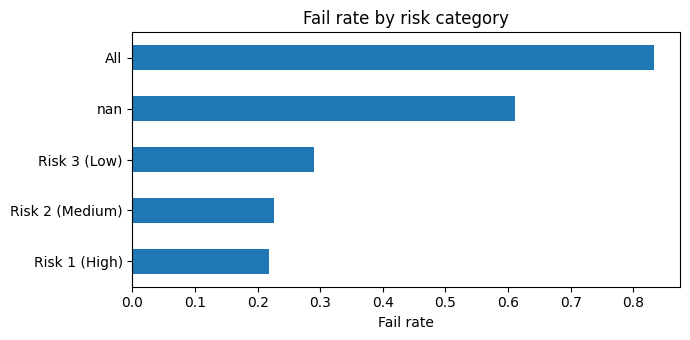

In [12]:
risk = rate_table(df, 'risk', top=10)

fig, ax = plt.subplots(figsize=(7, 3.5))
risk['fail_rate'].plot.barh(ax=ax)
ax.set_xlabel('Fail rate')
ax.set_ylabel('')
ax.set_title('Fail rate by risk category')
save(fig, 'fail_rate_by_risk')
risk

### Categorical driver findings

- Inspection type has 94 cleaned values. Re-inspections fail at 6.9% to 11.5%, because they follow up on a problem that has usually been fixed. Complaint (35.2%) and license (33.9%) inspections fail more often than canvass (22.6%), the routine type.
- Facility type has 461 cleaned values, and restaurants account for 185,399 modeling rows (67.9%). Rows with no facility type fail at 53.0% (743 rows), so missing values should be kept as their own category.
- Risk 3 (Low) fails at 29.0%, above Risk 1 (High) at 21.8% and Risk 2 (Medium) at 22.6%. The city uses risk category to set how often an establishment is inspected, so low-risk establishments go longer between visits. The establishment history section checks whether the gap explains the difference.
- 36 modeling rows have no risk and 6 have the value All, which should be mapped to missing.

## Time trends

The dashed line marks the 2018-07-01 food code change. The shaded band marks March 2020 to June 2021, an approximate window for COVID-19 disruption to inspections.

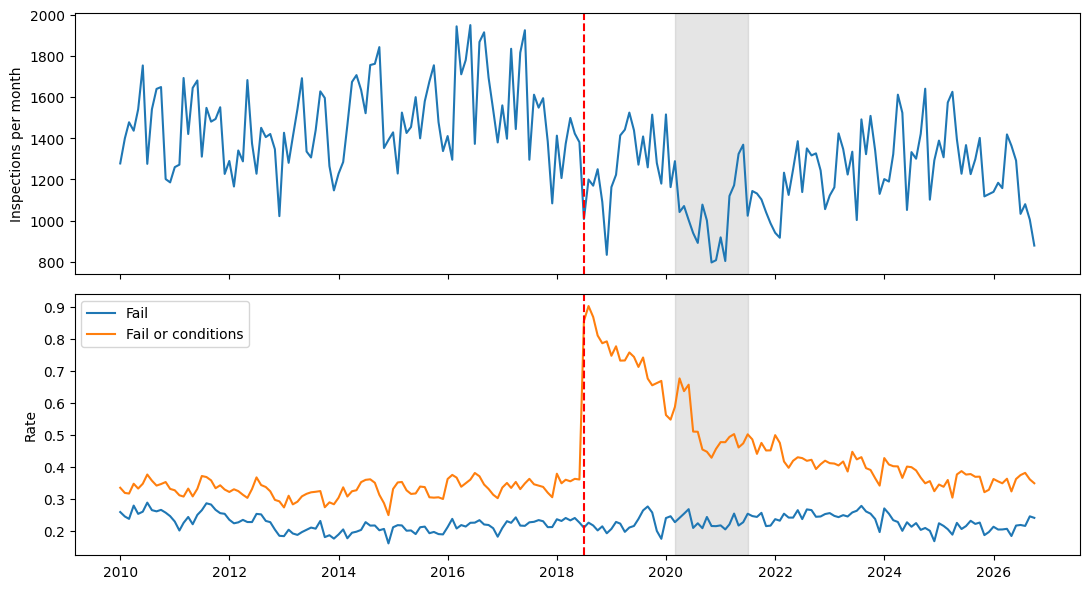

In [13]:
monthly = df.groupby(pd.Grouper(key='inspection_date', freq='MS')).agg(
    n=('fail', 'size'),
    fail_rate=('fail', 'mean'),
    fail_or_conditions_rate=('fail_or_conditions', 'mean'),
)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(monthly.index, monthly['n'])
axes[0].set_ylabel('Inspections per month')
axes[1].plot(monthly.index, monthly['fail_rate'], label='Fail')
axes[1].plot(monthly.index, monthly['fail_or_conditions_rate'], label='Fail or conditions')
axes[1].set_ylabel('Rate')
for ax in axes:
    ax.axvline(FOOD_CODE_CHANGE, color='red', linestyle='--')
    ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-06-30'), color='grey', alpha=0.2)
axes[1].legend(loc='upper left')
save(fig, 'monthly_volume_and_fail_rate')

In [14]:
yearly = df.groupby('year').agg(
    n=('fail', 'size'),
    fail_rate=('fail', 'mean'),
    fail_or_conditions_rate=('fail_or_conditions', 'mean'),
)
yearly.round(3)

,n,fail_rate,fail_or_conditions_rate
year,,,
2010,17382,0.259,0.341
2011,17584,0.248,0.334
2012,16018,0.227,0.323
2013,17068,0.196,0.299
2014,18621,0.200,0.324
2015,17892,0.202,0.322
2016,19860,0.216,0.349
2017,18499,0.223,0.338
2018,14849,0.223,0.571


In [15]:
rate_table(df, df['inspection_date'].dt.day_name(), top=7)

,n,fail_rate
inspection_date,,
Tuesday,62070,0.231
Thursday,60754,0.226
Friday,52539,0.214
Wednesday,51845,0.219
Monday,45606,0.230
Saturday,115,0.235
Sunday,12,0.250


### Time trend findings

- The monthly Fail rate stays between about 0.16 and 0.29 over the whole period, and the yearly rate ranges from 0.196 (2013) to 0.259 (2010), with no visible step at the 2018 food code change.
- The Fail or Pass w/ Conditions rate is near 0.33 before July 2018, jumps to about 0.9 in the month the new code took effect, and declines back to 0.353 by 2025. Because the Fail share is flat, the extra positives are inspections that moved from Pass to Pass w/ Conditions (the Pass w/ Conditions share is 0.115 in 2017, 0.493 in 2019, and 0.142 in 2025). This most likely reflects how inspectors applied the new code, and a model trained on the combined target would face several years of concept drift unrelated to establishment behavior. Fail is the more stable target.
- Monthly volume ranges from about 1,000 to 1,950 inspections before July 2018. It falls below 1,000 in early 2019 and in parts of 2020 and 2021, and recovers during 2022. The yearly Fail rate in 2020 (0.233) and 2021 (0.231) shows no detectable change from 2019 (0.224).
- Almost all inspections take place Monday to Friday (127 weekend rows), and weekday Fail rates range from 0.214 to 0.231, so day of week carries little signal.

## Violations field

Each inspection lists its violations separated by ` | `, and each entry starts with a numbered code such as `49.`. The inspector writes this field during the visit, so it describes the outcome and cannot be a feature for the same inspection. Codes from earlier inspections of the same establishment are usable history.

The checks below test whether the 2018 renumbering is visible in the data. Codes 46 to 63 should appear only after the change, and code 70 (the old smoking violation) only before it.

In [16]:
CODE_RE = re.compile(r'(?:^|\|)\s*(\d{1,2})\.')


def parse_codes(text):
    """Return the list of violation code numbers cited in one inspection."""
    if pd.isna(text):
        return []
    return [int(c) for c in CODE_RE.findall(text)]


df['violation_codes'] = df['violations'].map(parse_codes)
df['n_violations'] = df['violation_codes'].str.len()

df.groupby('results')['n_violations'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
results,,,,,,,,
Fail,61209.0,6.25,4.09,0.0,3.0,6.0,8.0,40.0
Pass,164640.0,2.39,2.18,0.0,1.0,2.0,4.0,23.0
Pass w/ Conditions,47092.0,5.26,3.24,0.0,3.0,5.0,7.0,30.0


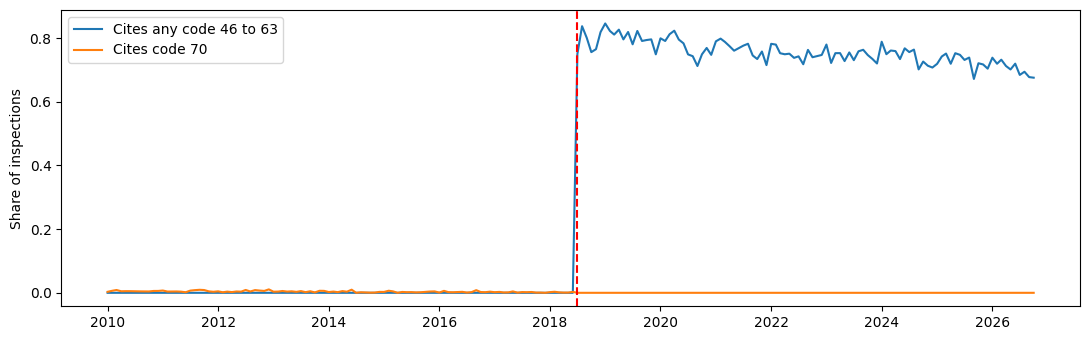

In [17]:
NEW_ONLY_CODES = set(range(46, 64))
df['cites_46_to_63'] = df['violation_codes'].map(lambda cs: any(c in NEW_ONLY_CODES for c in cs))
df['cites_70'] = df['violation_codes'].map(lambda cs: 70 in cs)

code_flags = df.set_index('inspection_date').resample('MS')[['cites_46_to_63', 'cites_70']].mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(code_flags.index, code_flags['cites_46_to_63'], label='Cites any code 46 to 63')
ax.plot(code_flags.index, code_flags['cites_70'], label='Cites code 70')
ax.axvline(FOOD_CODE_CHANGE, color='red', linestyle='--')
ax.set_ylabel('Share of inspections')
ax.legend(loc='upper left')
save(fig, 'violation_code_break_2018')

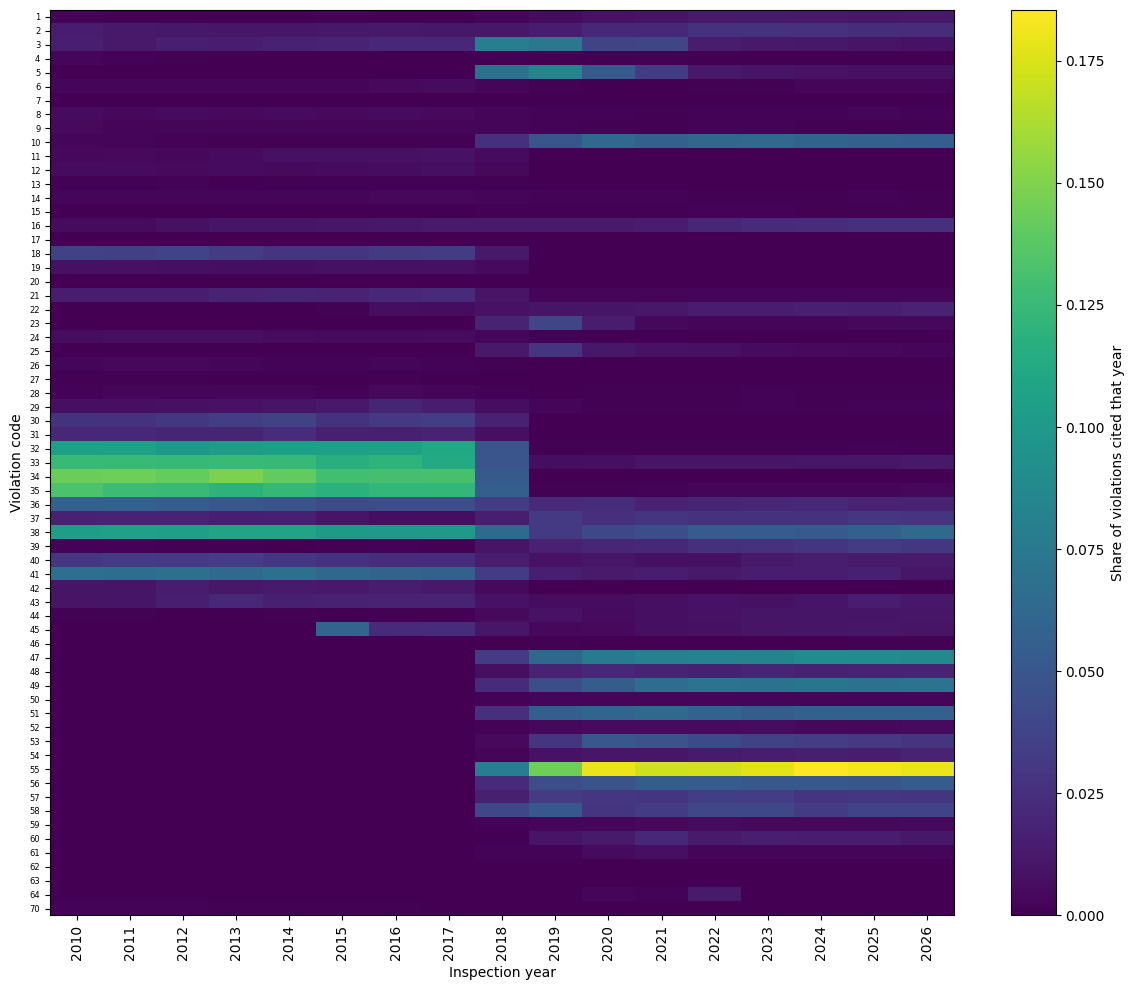

In [18]:
codes = df[['inspection_date', 'violation_codes']].explode('violation_codes').dropna()
codes['violation_codes'] = codes['violation_codes'].astype(int)

code_year = pd.crosstab(codes['violation_codes'], codes['inspection_date'].dt.year, normalize='columns')

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(code_year.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(code_year.columns)), code_year.columns, rotation=90)
ax.set_yticks(range(len(code_year.index)), code_year.index, fontsize=6)
ax.set_xlabel('Inspection year')
ax.set_ylabel('Violation code')
fig.colorbar(im, ax=ax, label='Share of violations cited that year')
save(fig, 'violation_code_share_by_year')

### Violations findings

- The renumbering is sharp. Codes 46 to 63 appear in no inspection before July 2018 and in about 67% to 85% of inspections per month afterwards, and code 70 disappears after the change.
- Codes 1 to 45 continue under the new code with new meanings. Code 34, for example, accounts for about 15% of cited violations before 2018 and almost none after, while code 10 grows from near zero to about 6%. A code number therefore means different things on each side of the boundary, so code-based history features need a crosswalk between the two schemes or must use post-change inspections only.
- Code 55 is the most cited code from 2020 onward, at about 17% to 18% of violations. Code 64 appears only between 2020 and 2022.
- Fail inspections cite a mean of 6.25 violations, Pass w/ Conditions 5.26, and Pass 2.39. The minimum for every result is zero, so some Fail rows have no parsed codes. The cell below counts these rows by result and period, which separates an empty field from a parsing gap in one coding scheme.

In [19]:
df['period'] = np.where(df['inspection_date'] < FOOD_CODE_CHANGE, 'before 2018-07-01', 'from 2018-07-01')
no_codes = df.assign(no_codes=df['n_violations'] == 0, field_empty=df['violations'].isna())

no_codes.pivot_table(index='results', columns='period', values=['no_codes', 'field_empty'],
                     aggfunc='mean').round(3)

field_empty                          no_codes                
period             before 2018-07-01 from 2018-07-01 before 2018-07-01 from 2018-07-01
results                                                                               
Fail                           0.088           0.026             0.088           0.026
Pass                           0.219           0.298             0.219           0.298
Pass w/ Conditions             0.009           0.026             0.009           0.026

### Empty violations findings

The share of rows with no parsed codes equals the share with an empty violations field for every result and period, so the parser reads codes from every non-empty field in both coding schemes. Empty fields are common for Pass (21.9% before the change, 29.8% after) and rare for Pass w/ Conditions (0.9% and 2.6%). Fail inspections with no recorded violations make up 8.8% of Fail rows before the change and 2.6% after, which is a recording gap in the source data. Violations describe the outcome of the visit and are excluded as same-inspection features, so these rows stay in the data.

## Establishment history

Inspections are linked over time by license number, with missing and zero licenses excluded. The previous result and the gap since the last inspection are known before a visit, so they are candidate features. This section uses the modeling rows only, so visits that ended as Out of Business or No Entry do not count as a previous inspection.

In [20]:
valid_license = df['license_number'].notna() & ~df['license_number'].str.strip().isin(['0', '0.0'])
hist = df[valid_license].sort_values(['license_number', 'inspection_date', 'inspection_id']).copy()

by_license = hist.groupby('license_number')
hist['prev_result'] = by_license['results'].shift(1).fillna('first inspection')
hist['days_since_prev'] = by_license['inspection_date'].diff().dt.days
hist['n_prior'] = by_license.cumcount()

print('Licenses:', hist['license_number'].nunique())
by_license.size().describe().round(1)

Licenses: 43958


,0
count,43958.0
mean,6.2
std,7.1
min,1.0
25%,1.0
50%,3.0
75%,8.0
max,185.0


In [21]:
rate_table(hist, 'prev_result', top=5)

,n,fail_rate
prev_result,,
Pass,130388,0.224
Fail,59484,0.117
first inspection,43958,0.334
Pass w/ Conditions,38367,0.265


In [22]:
gap_bins = [0, 7, 30, 90, 180, 365, 730, np.inf]
gap_labels = ['0-7', '8-30', '31-90', '91-180', '181-365', '366-730', '730+']
hist['gap_bucket'] = pd.cut(hist['days_since_prev'], bins=gap_bins, labels=gap_labels, include_lowest=True)

hist.groupby('gap_bucket', observed=True)['fail'].agg(n='size', fail_rate='mean').round(3)

,n,fail_rate
gap_bucket,,
0-7,36758,0.103
8-30,27616,0.100
31-90,11512,0.189
91-180,20002,0.253
181-365,71099,0.241
366-730,52133,0.244
730+,9119,0.288


### Establishment history findings

- 43,958 licenses have at least one modeling inspection. The median license has 3 inspections and a quarter have only 1, so history features are missing for many rows. A license's first inspection fails at 33.4%.
- After a Fail, the next inspection fails only 11.7% of the time, and inspections within 30 days of the previous one fail about 10% of the time. Both patterns match re-inspections, which follow a failure within days and usually pass.
- Beyond 30 days, the fail rate rises with the gap, from 0.189 at 31 to 90 days to 0.288 after two years.

The cell below separates the history effect from inspection type, and adds a count of earlier fails as a second candidate feature. The tables use the inspection groups defined earlier.

In [23]:
hist['prior_fails'] = hist.groupby('license_number')['fail'].cumsum() - hist['fail']
hist['prior_fails_capped'] = hist['prior_fails'].clip(upper=5)

print('Fail rate by previous result and inspection group')
display(hist.pivot_table(index='prev_result', columns='inspection_group', values='fail', aggfunc='mean').round(3))
print('Rows by previous result and inspection group')
display(pd.crosstab(hist['prev_result'], hist['inspection_group']))
print('Canvass inspections by number of earlier fails (5 means 5 or more)')
rate_table(hist[hist['inspection_group'] == 'canvass'], 'prior_fails_capped', top=6).sort_index()

Fail rate by previous result and inspection group


inspection_group,canvass,complaint,license,other,re-inspection
prev_result,,,,,
Fail,0.290,0.410,0.369,0.559,0.103
Pass,0.211,0.279,0.192,0.071,0.058
Pass w/ Conditions,0.284,0.342,0.251,0.023,0.012
first inspection,0.225,0.332,0.366,0.446,0.226


Rows by previous result and inspection group


inspection_group,canvass,complaint,license,other,re-inspection
prev_result,,,,,
Fail,954,371,1660,272,56227
Pass,97120,27786,4269,622,591
Pass w/ Conditions,24792,8285,892,922,3476
first inspection,9526,2391,31151,726,164


Canvass inspections by number of earlier fails (5 means 5 or more)


,n,fail_rate
prior_fails_capped,,
0,55623,0.186
1,34082,0.222
2,18127,0.253
3,9973,0.272
4,5687,0.301
5,8900,0.340


### History check findings

- Within each inspection group, a previous Fail raises the fail rate. For canvass inspections, the fail rate is 0.290 after a Fail, 0.284 after Pass w/ Conditions, 0.211 after a Pass, and 0.225 for a first inspection. The low overall rate after a Fail (0.117) comes from re-inspections, which make up 56,227 of the 59,484 inspections that follow a Fail.
- Few canvass inspections follow a Fail directly (954 rows), because a failure is usually followed by a re-inspection. The count of earlier fails reaches further back, and canvass fail rates rise steadily with it, from 0.186 with no earlier fails to 0.340 with five or more. This count is a strong candidate feature alongside the previous result.

The next cell tests whether Risk 3 establishments fail more often because they go longer between inspections. It limits the comparison to canvass inspections, so re-inspections and complaints do not affect the result.

In [24]:
canvass_hist = hist[hist['inspection_group'] == 'canvass']
canvass_hist.groupby('risk').agg(
    n=('fail', 'size'),
    fail_rate=('fail', 'mean'),
    median_days_since_prev=('days_since_prev', 'median'),
).round(3)

,n,fail_rate,median_days_since_prev
risk,,,
Risk 1 (High),108797,0.229,339.0
Risk 2 (Medium),19331,0.205,410.0
Risk 3 (Low),4264,0.261,703.0


### Risk check findings

Among canvass inspections, Risk 3 still fails most often (0.261 on 4,264 rows), against 0.229 for Risk 1 and 0.205 for Risk 2. Risk 3 establishments also have the longest median gap since their previous inspection (703 days, against 339 for Risk 1 and 410 for Risk 2). The gap does not explain the full ordering, because Risk 2 has a longer gap than Risk 1 and a lower fail rate. Risk category and days since the previous inspection both go into the feature set, so the model can weigh them jointly.

### History features across the 2018 change

The candidate features above are built from results and dates, which the 2018 renumbering does not change, so a model using only them would not see the change in its inputs. The next cell tests one history feature that depends on how inspections were recorded: the number of violations cited at the establishment's previous inspection. A step in its monthly mean at July 2018 means the change reaches the model inputs, which gives the monitoring stage a real shift to detect. The table checks whether the count predicts failure on canvass inspections after the change.

,count,mean,std,min,25%,50%,75%,max
period,,,,,,,,
before 2018-07-01,63775.0,2.92,2.18,0.0,1.0,3.0,4.0,18.0
from 2018-07-01,59091.0,3.26,3.04,0.0,1.0,3.0,5.0,28.0


,n,fail_rate
prev_n_violations,,
0.0,10162,0.185
1.0,9273,0.198
2.0,9630,0.211
3.0,8170,0.228
4.0,6305,0.258
5.0,4484,0.268
6.0,3299,0.294
7.0,2329,0.319
8.0,1651,0.337


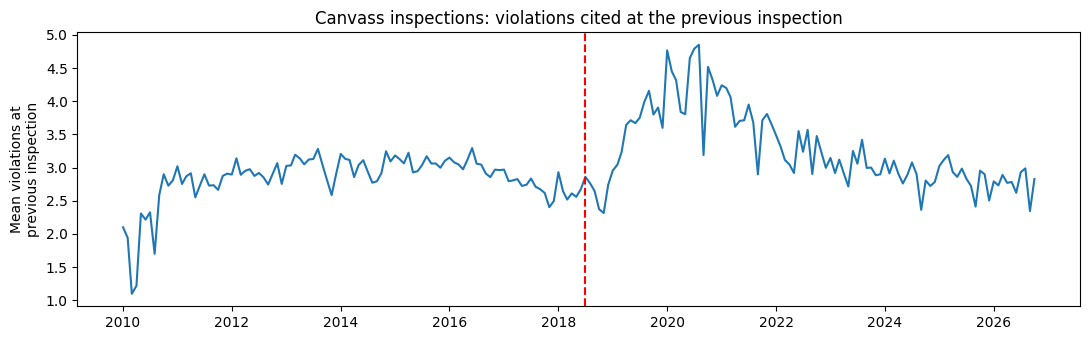

In [25]:
hist['prev_n_violations'] = hist.groupby('license_number')['n_violations'].shift(1)
canvass_hist = hist[hist['inspection_group'] == 'canvass']

prev_viol = canvass_hist.groupby(pd.Grouper(key='inspection_date', freq='MS'))['prev_n_violations'].mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(prev_viol.index, prev_viol)
ax.axvline(FOOD_CODE_CHANGE, color='red', linestyle='--')
ax.set_ylabel('Mean violations at\nprevious inspection')
ax.set_title('Canvass inspections: violations cited at the previous inspection')
save(fig, 'prev_violations_by_month')

display(canvass_hist.groupby('period')['prev_n_violations'].describe().round(2))

# Fail rate by previous violation count, canvass inspections from 2018-07-01 (10 means 10 or more).
post = canvass_hist[canvass_hist['period'] == 'from 2018-07-01']
rate_table(post, post['prev_n_violations'].clip(upper=10), top=12).sort_index()

### History feature findings

- The monthly mean shows no step at July 2018. It stays between about 2.5 and 3.3 from 2011 to mid-2018, rises through 2019 to a peak near 4.8 in 2020, returns to about 3 by 2023, and stays between about 2.4 and 3.2 through 2026. The rise lags the change because a canvass visit's previous inspection falls under the new code only once the gap between visits has passed (median 339 days for Risk 1). The low values in 2010 come from the start of the export, where only inspections from the same year can count as a previous inspection.
- Before the change, canvass inspections have a mean previous count of 2.92 (standard deviation 2.18, maximum 18, 63,775 rows). From the change onward, the mean is 3.26 (standard deviation 3.04, maximum 28, 59,091 rows), with the same median of 3 and a 75th percentile of 5 against 4.
- After the change, the canvass fail rate rises with the previous count, from 0.185 with no previous violations to 0.339 with nine and 0.425 with ten or more. The 496 rows with no previous inspection fail at 0.244.
- The count predicts failure and its distribution moves after the change, so it carries the 2018 change into the model inputs. The shift is concentrated in 2019 to 2021, inside the training window, and months from 2023 onward sit close to the pre-change level, so this feature alone separates the pre-change batch from recent training data only weakly.

## Geography

In [26]:
zip_rates = df.groupby('zip')['fail'].agg(n='size', fail_rate='mean')
zip_rates = zip_rates[zip_rates['n'] >= 500].sort_values('fail_rate')

print('ZIP codes with at least 500 inspections:', len(zip_rates))
pd.concat([zip_rates.head(5), zip_rates.tail(5)]).round(3)

ZIP codes with at least 500 inspections: 58


,n,fail_rate
zip,,
60666,3852,0.125
60606,4244,0.142
60638,3761,0.147
60601,4618,0.149
60604,1679,0.155
60636,3093,0.280
60651,3801,0.282
60620,5201,0.283
60628,4884,0.284


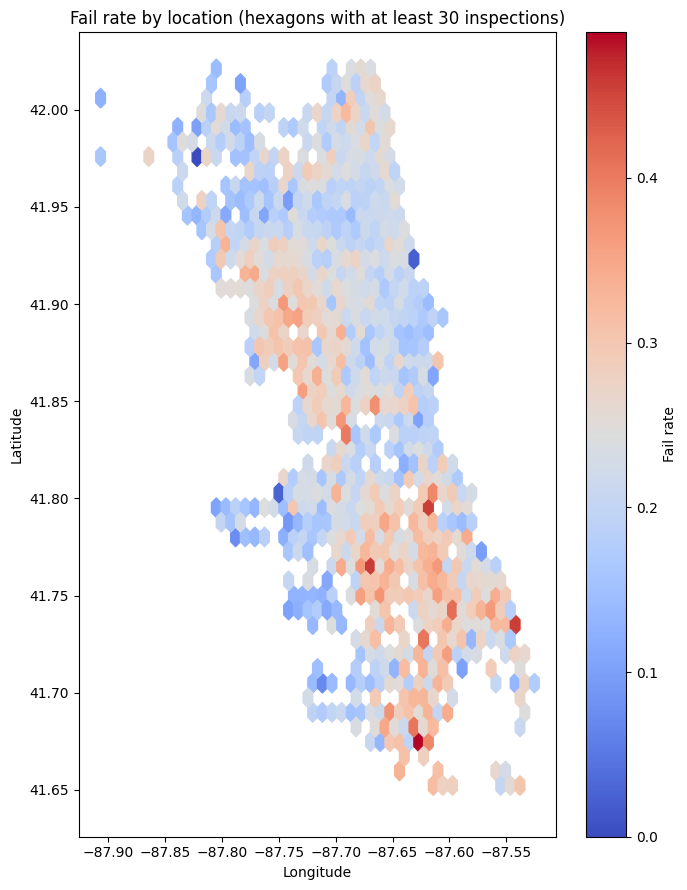

In [27]:
geo = df.dropna(subset=['latitude', 'longitude'])

fig, ax = plt.subplots(figsize=(7, 9))
hb = ax.hexbin(geo['longitude'], geo['latitude'], C=geo['fail'], reduce_C_function=np.mean,
               gridsize=45, mincnt=30, cmap='coolwarm')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Fail rate by location (hexagons with at least 30 inspections)')
fig.colorbar(hb, ax=ax, label='Fail rate')
save(fig, 'fail_rate_map')

### Geography findings

- 58 ZIP codes have at least 500 inspections. Their fail rates range from 0.125 (60666, O'Hare airport) to 0.297 (60619). The five highest are South Side and West Side ZIP codes (60619, 60628, 60620, 60651, 60636), and the lowest include downtown ZIP codes (60601, 60604, 60606).
- The map shows the same pattern, with higher fail rates on the South and West Sides. ZIP code, or a trailing fail rate for the establishment's ZIP code computed from earlier inspections only, is a candidate feature.

## Split and baselines

The split trains on inspections from 2018-07-01 onward and holds out the last 12 months of the export as the test set. The last 12 months of the training window serve as a validation window for the baselines below. Inspections before 2018-07-01 form a separate batch for the drift demonstration, because they use the old violation codes. The table sizes each part, using the linked rows from the history section (licenses that are missing or zero are excluded).

In [28]:
TEST_START = df['inspection_date'].max() - pd.DateOffset(months=12)

hist['split'] = np.select(
    [hist['inspection_date'] < FOOD_CODE_CHANGE, hist['inspection_date'] > TEST_START],
    ['pre-2018 drift batch', 'test'],
    default='train',
)
hist.groupby('split').agg(
    n=('fail', 'size'),
    fail_rate=('fail', 'mean'),
    start=('inspection_date', 'min'),
    end=('inspection_date', 'max'),
)

,n,fail_rate,start,end
split,,,,
pre-2018 drift batch,150789,0.221568,2010-01-04,2018-06-29
test,13856,0.207852,2025-10-30,2026-10-29
train,107552,0.229535,2018-07-03,2025-10-29


### Split findings

The linked rows divide into 107,552 training inspections (2018-07-03 to 2025-10-29, fail rate 0.230), 13,856 test inspections (2025-10-30 to 2026-10-29, fail rate 0.208), and 150,789 pre-change inspections for the drift batch (2010-01-04 to 2018-06-29, fail rate 0.222). The fail rate stays between 0.208 and 0.230 across the three parts, so the drift batch tests feature and schema drift against a stable target rate.

The README evaluates the model by precision@k, the fail rate among the k inspections the model ranks highest. The cell below scores single-feature baselines on a validation window, the last 12 months of the training period, with category fail rates taken from the training rows before it. The test year stays unscored until production validation. Each validation row gets the fail rate of its category, ties are broken at random, and k is set to 10% of the validation rows as a placeholder.

The baselines are scored twice, once on all validation inspections and once on canvass inspections only. Complaint, license, and re-inspection visits are triggered by events and take place whether or not a model ranks them, so canvass inspections are the population the city can actually prioritize. Any trained model has to beat these numbers.

In [29]:
rng = np.random.default_rng(42)
BASELINE_FEATURES = ['risk', 'facility_type_clean', 'inspection_group', 'zip', 'prev_result']


def precision_at_k(scores, y, frac=0.10):
    """Fail rate among the top `frac` share of rows ranked by score."""
    k = max(1, int(frac * len(y)))
    top = np.argsort(-np.asarray(scores, dtype=float), kind='stable')[:k]
    return float(np.asarray(y)[top].mean())


def score_baselines(fit_rows, eval_rows, frac=0.10):
    """Precision@k for each single-feature baseline, plus random ranking and the base rate."""
    out = {}
    for col in BASELINE_FEATURES:
        rates = fit_rows.groupby(col, dropna=False)['fail'].mean()
        scores = eval_rows[col].map(rates).fillna(fit_rows['fail'].mean()).to_numpy(dtype=float)
        # A tiny random jitter breaks ties between rows in the same category.
        out[col] = precision_at_k(scores + rng.random(len(scores)) * 1e-9, eval_rows['fail'], frac)
    out['random'] = precision_at_k(rng.random(len(eval_rows)), eval_rows['fail'], frac)
    out['base rate'] = eval_rows['fail'].mean()
    return out


# Category rates come from the training window before the last 12 months, and the baselines
# are scored on those 12 months. The test set stays unscored until production validation.
VALID_START = TEST_START - pd.DateOffset(months=12)
train = hist[hist['split'] == 'train']
fit = train[train['inspection_date'] <= VALID_START]
valid = train[train['inspection_date'] > VALID_START]
is_canvass = lambda frame: frame['inspection_group'] == 'canvass'

for name, rows in [('Fit', fit), ('Validation', valid)]:
    print(f'{name}: {len(rows):,} rows ({is_canvass(rows).sum():,} canvass), '
          f'{rows.inspection_date.min().date()} to {rows.inspection_date.max().date()}')

pd.DataFrame({
    'all inspections': score_baselines(fit, valid),
    'canvass only': score_baselines(fit[is_canvass(fit)], valid[is_canvass(valid)]),
}).round(3)

Fit: 91,344 rows (44,596 canvass), 2018-07-03 to 2024-10-29
Validation: 16,208 rows (8,556 canvass), 2024-10-30 to 2025-10-29


,all inspections,canvass only
risk,0.214,0.223
facility_type_clean,0.214,0.242
inspection_group,0.312,0.223
zip,0.270,0.318
prev_result,0.251,0.276
random,0.201,0.221
base rate,0.210,0.223


### Baseline findings

- Category rates come from 91,344 training rows (2018-07-03 to 2024-10-29), and the validation window holds 16,208 rows (8,556 canvass) from 2024-10-30 to 2025-10-29. The validation base rate is 0.210 on all inspections and 0.223 on canvass inspections.
- On all inspections, ranking by inspection group gives the highest precision@k (0.312), because it puts license and complaint inspections first. Those visits are triggered by events, so the city cannot act on this ranking. ZIP code reaches 0.270 and previous result 0.251, while risk and facility type (both 0.214) show no detectable lift over the base rate.
- On canvass inspections, ZIP code ranks highest (0.318), followed by previous result (0.276) and facility type (0.242). Risk (0.223) shows no detectable lift. Inspection group has a single value on canvass rows, so its score is a random draw (0.223), and random ranking scores 0.221.
- With k at 10%, the all-inspections score uses 1,620 rows, which gives a standard error of about 0.010 near the base rate, and the canvass score uses 855 rows, with a standard error of about 0.014.

## Decisions

- Target: Fail. Its yearly rate stays between 0.196 and 0.259 from 2010 to 2026, while the Fail or Pass w/ Conditions rate more than doubles after the 2018 food code change and takes until about 2025 to return to its earlier level.
- Training window: inspections from 2018-07-01 onward (107,552 linked rows), so that violation-history features use one coding scheme.
- Validation window: the last 12 months of the training window (2024-10-30 to 2025-10-29). Baselines and model selection are scored on it.
- Test split: the last 12 months of the export (13,856 linked rows, 2025-10-30 to 2026-10-29), unscored until production validation.
- Drift demonstration: corrupted copies of the test set (out-of-range values, swapped columns, and an altered schema) sent through the deployed model, as the brief requires. The 2018 food code change is a real shift in the same data. The 150,789 pre-change inspections cite code 70 and none of codes 46 to 63, and their fail rate (0.222) is close to training (0.230). In the model inputs, the change shows up as a rise in the previous inspection's violation count from 2019 to 2021 that returns close to its pre-change level by 2023, so the corrupted test set is the main evidence that monitoring raises alerts.
- Unit of prediction: one row per inspection, with features computed only from earlier inspections of the same license.
- Candidate features: count of earlier fails, previous result, days since the previous inspection, inspection group, risk category, facility type, and a trailing ZIP code fail rate computed from earlier inspections only. ZIP code stays in the model only if it adds lift on the validation window. The previous inspection's violation count is added, because the canvass fail rate after the change rises from 0.185 with no previous violations to 0.425 with ten or more.
- Category cleanup: five inspection groups, and the 20 most common facility types (98.0% of rows) with the rest grouped as other. Missing facility type is kept as its own category, because those rows fail at 53.0%. Risk value All is mapped to missing.
- Evaluation metric: precision@k on canvass inspections. The best single-feature baseline on the validation window is ZIP code (0.318 against a base rate of 0.223), followed by previous result (0.276), which sets the bar for the trained model.

## Open decisions

- Prediction population: all inspections, or canvass inspections only. Complaint, license, and re-inspection visits take place whether or not a model ranks them, which supports canvass only.
- Value of k: 10% of validation rows is a placeholder. A value tied to inspector capacity, such as the number of canvass inspections per month, fits the use case better, and a larger k also lowers the noise in the metric.
- Code-based history features: licenses inspected before 2018 have history in the old codes. Result-based features (previous result, earlier fail count, days since the previous inspection) are unaffected, while code-based features need a crosswalk or must use post-change history only.
- Direction of the real drift replay: sending the pre-2018 batch to a model trained on later data runs backward in time. A forward replay trains a reference model on inspections before 2018-07-01 and serves the inspections that follow, which matches how the change happened.
- Nearby complaints: the README lists this feature. Complaint inspections in the same ZIP code over the previous 90 days can be computed from this dataset, while 311 complaint records would need a second source.

Assisting sources: Claude Opus 5.5 (Anthropic).